# Evidencia de aprendizaje 2 – Optimizando la productividad en el mundo del software

**Estudiante:** Alejandro Arango Calderón
**Curso:** Programación para Análisis de Datos – Grupo PREICA2602B020048
**Docente:** Andrés Felipe Palacio
**Institución:** Institución Universitaria Digital de Antioquia
**Fecha:** 4 de noviembre de 2026

Repositorio: https://github.com/Biershoot/monitor-precios-falabella

---

En la Evidencia 1 hice scraping de Falabella Colombia con BeautifulSoup, Selenium y Scrapy para
analizar qué tan competitivos son los audífonos **Xiaomi Redmi Buds 6 Play** frente al resto de
audífonos inalámbricos. Todo quedó en un notebook que había que correr a mano y que solo mostraba
los datos de un día.

En esta evidencia convertí ese trabajo en un **proyecto de software** (`monitor-precios-falabella`):

1. El código del scraper quedó organizado en un paquete de Python con funciones pequeñas.
2. Agregué **pruebas automatizadas** con pytest.
3. Todo se versiona con **Git** usando ramas `feature/*`, `fix/*`, `develop` y `main`.
4. Configuré un pipeline **CI/CD con GitHub Actions**: pruebas en cada push/PR, despliegue del
   tablero en **GitHub Pages** y un **scraping programado cada semana** que va guardando el historial.

En este notebook muestro el proceso paso a paso y ejecuto cada parte.

## 1. Preparación del entorno

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# El notebook puede estar en la carpeta notebooks/ del repositorio o junto al informe
if (Path.cwd() / "monitor-precios-falabella").exists():
    os.chdir(Path.cwd() / "monitor-precios-falabella")
elif Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))
print("Carpeta del proyecto:", Path.cwd())

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from monitor_precios import analisis, extraccion, limpieza, reporte
%matplotlib inline
os.environ["NO_COLOR"] = "1"   # para que ruff y pytest no impriman códigos de color
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

Carpeta del proyecto: C:\Users\alejo\Documents\S35 - Evidencia de aprendizaje 2. Optimizando la productividad en el mundo del software\monitor-precios-falabella


In [2]:
def ejecutar(comando):
    """Ejecuta un comando de la terminal y muestra la salida en el notebook."""
    r = subprocess.run(comando, shell=True, capture_output=True, text=True, encoding="utf-8",
                       errors="replace")
    print(r.stdout + r.stderr)
    return r.returncode

## 2. Estructura del proyecto

El proyecto está dividido en módulos según la responsabilidad de cada uno:

| Archivo | Responsabilidad |
|---|---|
| `monitor_precios/extraccion.py` | Revisa el robots.txt, descarga las páginas y lee el JSON `__NEXT_DATA__` |
| `monitor_precios/limpieza.py` | Quita repetidos, corrige precios y calcula el descuento |
| `monitor_precios/analisis.py` | Indicadores del artículo frente al catálogo e historial |
| `monitor_precios/reporte.py` | Gráficas y sitio estático que se publica en GitHub Pages |
| `monitor_precios/__main__.py` | Comandos `scrapear` y `reporte` |
| `tests/` | Pruebas automatizadas con pytest |
| `.github/workflows/` | Pipeline de CI/CD |

In [3]:
ejecutar("git ls-files")

.github/pull_request_template.md
.github/workflows/cd.yml
.github/workflows/ci.yml
.github/workflows/scraping.yml
.gitignore
README.md
datos/articulo_ultimo.json
datos/catalogo_ultimo.csv
datos/catalogos/catalogo_2026-10-22.csv
datos/catalogos/catalogo_2026-11-04.csv
datos/historial.csv
docs/flujo-devops.md
monitor_precios/__init__.py
monitor_precios/__main__.py
monitor_precios/analisis.py
monitor_precios/extraccion.py
monitor_precios/limpieza.py
monitor_precios/reporte.py
pyproject.toml
requirements-dev.txt
requirements.txt
tests/conftest.py
tests/test_extraccion.py
tests/test_limpieza_analisis.py
tests/test_reporte_cli.py



0

## 3. Metodología de scraping

Mantengo la metodología de la Evidencia 1, pero ahora cada paso es una función que se puede probar:

1. **Revisar el robots.txt** antes de extraer.
2. **Descargar** cada página con `requests` (User-Agent de navegador, idioma es-CO y pausa entre páginas).
3. **Leer el bloque `__NEXT_DATA__`** con BeautifulSoup. Falabella está hecho en Next.js y cada página
   trae todos los productos en un JSON, lo que es más estable que leer las clases CSS.
4. **Limpiar** los datos con pandas.
5. **Analizar** y comparar con el historial.

### 3.1 robots.txt

Aquí encontré un error interesante: al usar `robotparser.read()` el resultado era que **no** se
podía rastrear nada, aunque el archivo dice que todos los robots son bienvenidos. La razón es que
`read()` descarga el archivo con el User-Agent de urllib, el servidor responde 403 y robotparser
interpreta eso como "todo prohibido". Lo corregí en la rama `fix/robots-txt` descargando el archivo con
`requests` y usando `rp.parse()`.

In [4]:
from urllib import robotparser
url_busqueda = extraccion.URL_BUSQUEDA.format(busqueda="audifonos+inalambricos", pagina=1)

rp = robotparser.RobotFileParser(extraccion.BASE + "/robots.txt")
rp.read()
print("Con robotparser.read():      ", rp.can_fetch("*", url_busqueda))
print("Con la función corregida:    ", extraccion.puede_rastrear(url_busqueda))

Con robotparser.read():       False


Con la función corregida:     True


### 3.2 Extracción del catálogo (5 páginas de la búsqueda «audífonos inalámbricos»)

In [5]:
import time
inicio = time.time()
productos = extraccion.scrapear_catalogo("audifonos inalambricos", paginas=5, pausa=1.5)
print(f"{len(productos)} productos extraídos en {time.time() - inicio:.1f} s")
pd.DataFrame(productos).head()

260 productos extraídos en 9.9 s


,pagina,posicion,id_producto,nombre,marca,vendedor,precio_oferta,precio_normal,precio_cmr,calificacion,num_resenas,patrocinado,url
0,1,1,152884280,Audífonos Inalámbricos Ear (a) B162 Bluetooth ...,NOTHING,Solutions 2 Go,479900,599900,NaN,0.0000,0,True,https://www.falabella.com.co/falabella-co/prod...
1,1,2,141082333,Audífonos Inalambricos Bluetooth OnEar R3 Blancos,SUDIO,Techtex,119900,339900,NaN,0.0000,0,True,https://www.falabella.com.co/falabella-co/prod...
2,1,3,118373270,Audífonos Inalámbricos Bluetooth Livepods Lp40...,LENOVO,Audio Lenovo,53900,72900,NaN,4.0909,132,False,https://www.falabella.com.co/falabella-co/prod...
3,1,4,135820025,Audífonos wf-c510 true wireless tipo earbuds -...,SONY,Sony Colombia,189900,339900,NaN,4.5480,916,False,https://www.falabella.com.co/falabella-co/prod...
4,1,5,149940530,Audifonos SENSE LITE PURPURA BT,JBL,Techspot,327900,384900,NaN,0.0000,0,False,https://www.falabella.com.co/falabella-co/prod...


### 3.3 Ficha del artículo

In [6]:
articulo = extraccion.parsear_articulo(extraccion.descargar(extraccion.URL_ARTICULO))
articulo

{'id_producto': '73025565',
 'nombre': 'Audífonos earbuds Xiaomi Bluetooth Redmi Buds 6 Play',
 'marca': 'XIAOMI',
 'vendedor': 'FALABELLA',
 'precio_oferta': 59900,
 'precio_normal': 99900,
 'url': 'https://www.falabella.com.co/falabella-co/product/73025565/Audifonos-earbuds-Xiaomi-Bluetooth-Redmi-Buds-6-Play-Ng'}

### 3.4 Limpieza

In [7]:
catalogo = limpieza.limpiar_catalogo(productos)
print("Registros antes de limpiar:", len(productos))
print("Registros después de limpiar:", len(catalogo))
print("Valores vacíos en campos clave:")
print(catalogo[["id_producto", "nombre", "marca", "precio_oferta", "precio_normal"]].isna().sum())
catalogo[["nombre", "marca", "vendedor", "precio_oferta", "precio_normal", "descuento_pct",
          "calificacion", "num_resenas"]].head(10)

Registros antes de limpiar: 260
Registros después de limpiar: 249
Valores vacíos en campos clave:
id_producto      0
nombre           0
marca            0
precio_oferta    0
precio_normal    0
dtype: int64


,nombre,marca,vendedor,precio_oferta,precio_normal,descuento_pct,calificacion,num_resenas
0,Audífonos Inalámbricos Ear (a) B162 Bluetooth ...,NOTHING,Solutions 2 Go,479900,599900,20.0,0.0000,0
1,Audífonos Inalambricos Bluetooth OnEar R3 Blancos,SUDIO,Techtex,119900,339900,64.7,0.0000,0
2,Audífonos Inalámbricos Bluetooth Livepods Lp40...,LENOVO,Audio Lenovo,53900,72900,26.1,4.0909,132
3,Audífonos wf-c510 true wireless tipo earbuds -...,SONY,Sony Colombia,189900,339900,44.1,4.5480,916
4,Audifonos SENSE LITE PURPURA BT,JBL,Techspot,327900,384900,14.8,0.0000,0
5,Audifonos Inalambricos Bluetooth 4ta Generació...,GENERICO,Gawe Col,89900,179900,50.0,0.0000,0
6,Combo Smart HW8 + Audífonos Inalámbricos – Tec...,GENERICO,Enlazo1,79900,120000,33.4,0.0000,0
7,By Anker P20i - Auriculares inalámbricos,SOUNDCORE,Distribuciones Ip,109900,159900,31.3,0.0000,0
8,Audífonos bluetooth 1Hora Bluetooth AUT211,1 HORA,Falabella,59900,119900,50.0,4.5610,41
9,Audifonos ultima generación pro - inalámbricos...,GENERICO,Empire,79900,180000,55.6,2.3333,3


## 4. Resultados del análisis

In [8]:
indicadores = analisis.indicadores_articulo(catalogo, articulo)
pd.Series(indicadores, name="valor").to_frame()

,valor
productos_catalogo,249.0
precio_articulo,59900.0
precio_mediano_catalogo,74999.0
pct_mas_baratos_que_articulo,33.3
descuento_articulo,40.0
descuento_promedio_catalogo,27.3
pct_patrocinados,5.6


In [9]:
resumen = analisis.resumen_marcas(catalogo)
resumen

,marca,productos,precio_mediano,descuento_prom,resenas_totales
0,GENERICO,111,79900.0,21.4,17
1,JBL,16,198400.0,18.8,527
2,FLY,13,52900.0,38.9,0
3,LENOVO,11,53900.0,26.1,541
4,MOVISUN,10,99900.0,15.0,0
5,ZHOPI CO,9,30900.0,41.2,0
6,SONY,7,159900.0,32.4,3639
7,IFROGZ,7,189900.0,39.2,5
8,XIAOMI,5,60000.0,18.5,2295
9,1HORA,5,60900.0,34.0,0


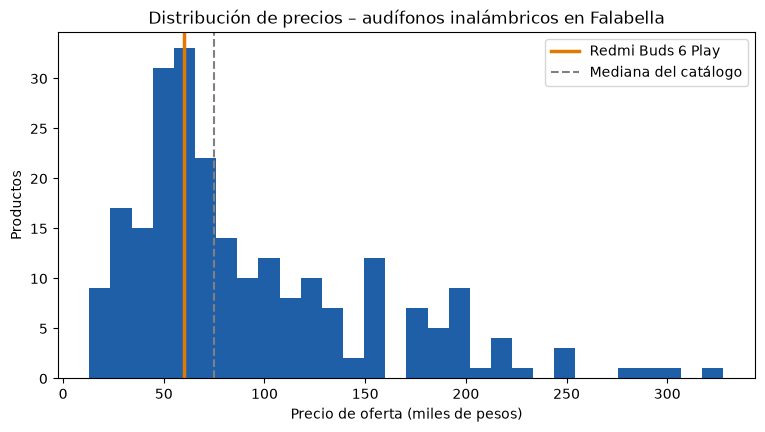

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
limite = catalogo["precio_oferta"].quantile(0.95)
ax.hist(catalogo.loc[catalogo.precio_oferta <= limite, "precio_oferta"] / 1000, bins=30, color="#1f5fa8")
ax.axvline(articulo["precio_oferta"] / 1000, color="#e07b00", lw=2.5, label="Redmi Buds 6 Play")
ax.axvline(catalogo.precio_oferta.median() / 1000, color="gray", ls="--", label="Mediana del catálogo")
ax.set_xlabel("Precio de oferta (miles de pesos)")
ax.set_ylabel("Productos")
ax.set_title("Distribución de precios – audífonos inalámbricos en Falabella")
ax.legend()
plt.show()

### 4.1 Comparación con la Evidencia 1

El historial (`datos/historial.csv`) tiene una fila por cada fecha de extracción. La primera fila son los
datos de la Evidencia 1 (22 de octubre, temporada HOT SALE) y la segunda la extracción con el nuevo
scraper. El workflow `scraping.yml` agrega una fila nueva cada lunes.

In [11]:
historial = pd.read_csv("datos/historial.csv")
fila_hoy = analisis.fila_historial("2026-11-04", indicadores)
historial = analisis.agregar_historial(historial, fila_hoy)
historial

,fecha,productos,precio_mediano,descuento_promedio,precio_articulo,pct_mas_baratos
0,2026-10-22,256,85499.5,29.8,59900,26.6
1,2026-11-04,249,74999.0,27.3,59900,33.3


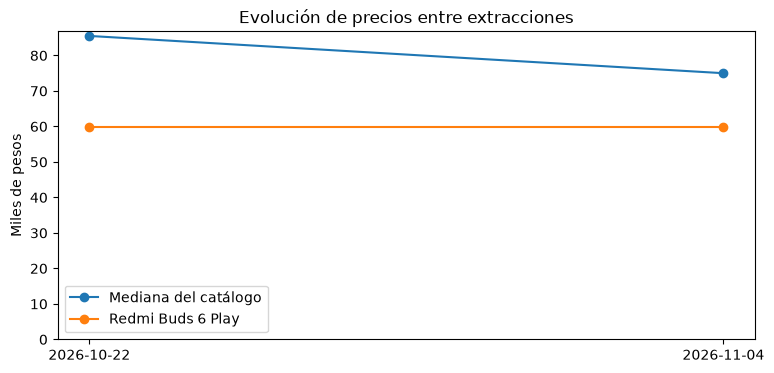

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(historial.fecha, historial.precio_mediano / 1000, "o-", label="Mediana del catálogo")
ax.plot(historial.fecha, historial.precio_articulo / 1000, "o-", label="Redmi Buds 6 Play")
ax.set_ylim(bottom=0)
ax.set_ylabel("Miles de pesos")
ax.set_title("Evolución de precios entre extracciones")
ax.legend()
plt.show()

## 5. Pruebas automatizadas

Las pruebas están en `tests/` y **no usan internet**: `conftest.py` arma páginas HTML con la misma
estructura de Falabella y con `monkeypatch` reemplazo la descarga. Se prueban:

- la conversión de precios (`a_numero`) con varios casos usando `parametrize`,
- la lectura de la búsqueda y de la ficha del artículo,
- que el scraper se detenga cuando una página viene vacía,
- el respeto del robots.txt,
- la limpieza (repetidos, precios vacíos, descuentos),
- los indicadores y el historial,
- la generación del sitio y el flujo completo de los comandos `scrapear` y `reporte`.

In [13]:
ejecutar(f'"{sys.executable}" -m ruff check .')

All checks passed!



0

In [14]:
ejecutar(f'"{sys.executable}" -m pytest --cov --cov-report=term-missing --color=no')

============================= test session starts =============================
platform win32 -- Python 3.12.10, pytest-9.2.0, pluggy-1.7.0 -- C:\Users\alejo\AppData\Local\Programs\Python\Python312\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\alejo\Documents\S35 - Evidencia de aprendizaje 2. Optimizando la productividad en el mundo del software\monitor-precios-falabella
configfile: pyproject.toml
testpaths: tests
plugins: anyio-4.15.1, platformdirs-4.13.5, cov-7.1.0
collecting ... collected 28 items

tests/test_extraccion.py::test_a_numero[$ 59.900-59900] PASSED           [  3%]
tests/test_extraccion.py::test_a_numero[1.299.900-1299900] PASSED        [  7%]
tests/test_extraccion.py::test_a_numero[99900-99900] PASSED              [ 10%]
tests/test_extraccion.py::test_a_numero[-None] PASSED                    [ 14%]
tests/test_extraccion.py::test_a_numero[None-None] PASSED                [ 17%]
tests/test_extraccion.py::test_a_numero[sin precio-None] PASSED          [ 21%]
tests

0

## 6. Control de versiones con Git

Ramas usadas:

- `main`: versión estable, lo que llega aquí se despliega.
- `develop`: integración.
- `feature/*`: una rama por funcionalidad. `fix/*`: correcciones.

Los mensajes de commit usan prefijos (`feat`, `fix`, `test`, `ci`, `docs`, `chore`, `datos`).

In [15]:
ejecutar("git branch -a")
ejecutar("git log --oneline --graph --all")

  develop
  feature/cd-pages
  feature/ci
  feature/datos-iniciales
* feature/documentacion
  feature/extraccion
  feature/limpieza-analisis
  feature/reporte
  fix/robots-txt
  main

* f9e84dc docs: explicación detallada del flujo de trabajo DevOps
* dc053db docs: README con estructura, uso y flujo DevOps
*   3786625 Merge branch 'feature/cd-pages' into develop
|\  
| * de2efe4 ci: scraping programado cada lunes con commit automático de datos
| * 6e8af05 ci: despliegue continuo del sitio en GitHub Pages
|/  
*   c3b0dbb Merge branch 'feature/datos-iniciales' into develop
|\  
| * 3971b7c datos: primera extracción con el nuevo scraper (2026-11-04)
| * 8e29c0d datos: catálogo de la Evidencia 1 (2026-10-22) como punto de partida
|/  
*   710126a Merge branch 'fix/robots-txt' into develop
|\  
| * 0b3c166 test: pruebas de robots.txt y de la decodificación UTF-8
| * 1e6fafe fix: leer robots.txt con requests en vez de robotparser.read()
|/  
*   c379268 Merge branch 'feature/ci' into develo

0

## 7. Pipeline CI/CD con GitHub Actions

Hay tres workflows en `.github/workflows/`:

| Workflow | Disparador | Qué hace |
|---|---|---|
| `ci.yml` | push a ramas de trabajo y pull requests | ruff + pytest (Python 3.11 y 3.12) con cobertura mínima de 85 % |
| `cd.yml` | push a `main` | vuelve a correr la CI, genera el sitio y lo publica en GitHub Pages |
| `scraping.yml` | cada lunes 7:00 a. m. (cron) | extrae datos nuevos, hace commit en `datos/` y vuelve a desplegar |

In [16]:
print(Path(".github/workflows/ci.yml").read_text(encoding="utf-8"))

# Integración continua: se ejecuta en cada push y en cada pull request.
# Si el lint o alguna prueba falla, el PR queda marcado en rojo y no se debe fusionar.
name: CI - pruebas

on:
  push:
    branches-ignore: [main]   # en main las pruebas las corre el workflow de CD
  pull_request:
    branches: [main, develop]
  workflow_call:

jobs:
  pruebas:
    name: Lint y pruebas (Python ${{ matrix.python }})
    runs-on: ubuntu-latest
    strategy:
      fail-fast: false
      matrix:
        python: ["3.11", "3.12"]
    steps:
      - name: Descargar el código
        uses: actions/checkout@v5

      - name: Instalar Python ${{ matrix.python }}
        uses: actions/setup-python@v6
        with:
          python-version: ${{ matrix.python }}
          cache: pip
          cache-dependency-path: requirements-dev.txt

      - name: Instalar dependencias
        run: pip install -r requirements-dev.txt

      - name: Revisar estilo con ruff
        run: ruff check .

      - name: Ejecutar pr

In [17]:
print(Path(".github/workflows/cd.yml").read_text(encoding="utf-8"))

# Despliegue continuo: cuando hay cambios en main (normalmente por un PR fusionado)
# se vuelven a correr las pruebas y, si pasan, se publica el sitio en GitHub Pages.
name: CD - despliegue en GitHub Pages

on:
  push:
    branches: [main]
  workflow_dispatch:
  workflow_call:

permissions:
  contents: read
  pages: write
  id-token: write

concurrency:
  group: pages
  cancel-in-progress: false

jobs:
  pruebas:
    uses: ./.github/workflows/ci.yml

  construir:
    name: Construir el sitio
    needs: pruebas
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v5
        with:
          ref: main          # para tomar también los datos que acaba de subir el scraping

      - uses: actions/setup-python@v6
        with:
          python-version: "3.12"
          cache: pip
          cache-dependency-path: requirements.txt

      - run: pip install -r requirements.txt

      - name: Generar el sitio estático
        run: python -m monitor_precios reporte --salida sitio



In [18]:
print(Path(".github/workflows/scraping.yml").read_text(encoding="utf-8"))

# Automatización: cada lunes se vuelve a hacer el scraping, se guardan los datos
# nuevos en el repositorio y se vuelve a publicar el sitio con el historial actualizado.
name: Scraping programado

on:
  schedule:
    - cron: "0 12 * * 1"   # lunes a las 12:00 UTC (7:00 a. m. en Colombia)
  workflow_dispatch:        # también se puede lanzar a mano desde la pestaña Actions

permissions:
  contents: write
  pages: write
  id-token: write

jobs:
  scrapear:
    name: Extraer datos y actualizar historial
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v5

      - uses: actions/setup-python@v6
        with:
          python-version: "3.12"
          cache: pip
          cache-dependency-path: requirements.txt

      - run: pip install -r requirements.txt

      - name: Ejecutar el scraper
        run: python -m monitor_precios scrapear --paginas 5 --pausa 2

      - name: Guardar los datos nuevos en el repositorio
        run: |
          git config user.name "github-ac

## 8. Sitio generado (lo que se despliega en GitHub Pages)

El mismo comando que corre GitHub Actions se puede ejecutar en local. Después tomo una captura
del sitio con Selenium (Edge sin ventana), igual que en la Evidencia 1.

In [19]:
ejecutar(f'"{sys.executable}" -m monitor_precios reporte --salida sitio')

Sitio generado en sitio\index.html



0

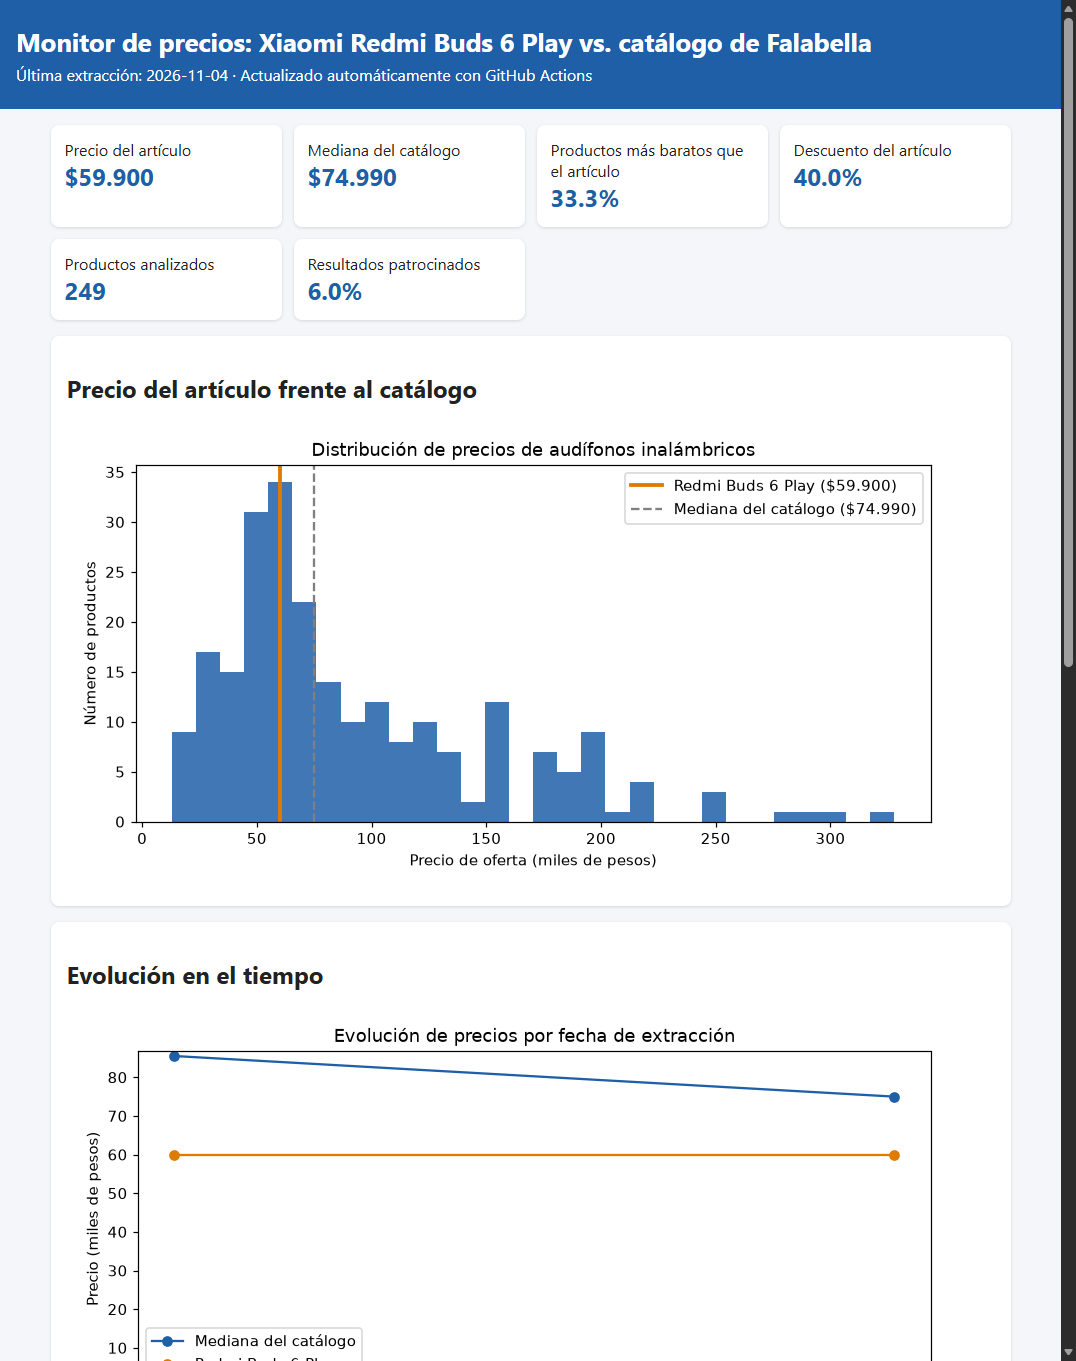

In [20]:
from selenium import webdriver

opciones = webdriver.EdgeOptions()
opciones.add_argument("--headless=new")
opciones.add_argument("--window-size=1100,1500")
driver = webdriver.Edge(options=opciones)
driver.get((Path("sitio") / "index.html").resolve().as_uri())
time.sleep(1)
driver.save_screenshot("sitio/captura_sitio.png")
driver.quit()
display(Image("sitio/captura_sitio.png", width=750))

## 9. Conclusiones

- Pasar el código del notebook a un **paquete con funciones pequeñas** fue lo que permitió hacer
  pruebas automatizadas; con el código todo junto en celdas no había forma de probar cada parte.
- Las **pruebas sin internet** (HTML de ejemplo + `monkeypatch`) hacen que la CI sea estable: no falla
  porque cambie un precio o porque Falabella tarde en responder.
- Trabajar con **ramas y merges** dejó un historial ordenado donde se ve qué se hizo en cada parte,
  incluido el error del robots.txt y su corrección en una rama `fix/`.
- Con **GitHub Actions** el proyecto se prueba, se publica y se actualiza solo. Esto resolvió la
  limitación de la Evidencia 1, donde el análisis era la foto de un solo día.
- En los datos: el artículo mantiene su precio de $59.900 (40 % de descuento), mientras que la mediana
  del catálogo bajó de unos $85.500 a unos $75.000 después del HOT SALE. Aun así sigue siendo más barato que cerca de
  2 de cada 3 audífonos inalámbricos de la tienda, aunque su ventaja se redujo (de 73 % a 67 %).